# 00 · Environment and Activations

Welcome. This is the first of six short notebooks that get you hands-on with the core mechanics behind
[`PROPOSAL.md`](../../PROPOSAL.md) before you start on a workstream. Every notebook here runs **on CPU,
in a couple of minutes, using a tiny model** (GPT-2 small) instead of the real research models
(`PROPOSAL.md` § 4.1); the goal is to build intuition for the *mechanics*, not to reproduce a real
result.

This notebook covers the one skill every workstream needs: loading a model and pulling its internal
activations out. See `PROPOSAL.md` § 4.2 ("we train sparse autoencoders on the residual stream at
intermediate layers"); this notebook is about the "residual stream" half of that sentence.

**Run top to bottom.** It should take under a minute after the model downloads once.

> You may see a `DeprecationWarning` about `HookedTransformer.from_pretrained` when you run this. It's
> benign: TransformerLens is mid-migration to a new API, but the method used here is still fully
> supported and is what most current tutorials and papers use.


In [1]:
import torch
from transformer_lens import HookedTransformer

torch.manual_seed(0)
device = "cpu"


## Load the model

`HookedTransformer` is TransformerLens's wrapper around a standard transformer that adds a "hook" at
every intermediate computation, so we can read (or later, edit) any internal value during a forward
pass. We use GPT-2 small (124M parameters) purely because it's small enough to run comfortably on a
laptop CPU; the real project uses larger, reasoning-specialized models instead.


In [2]:
model = HookedTransformer.from_pretrained("gpt2", device=device)

print(f"layers: {model.cfg.n_layers}")
print(f"residual stream width (d_model): {model.cfg.d_model}")
print(f"attention heads per layer: {model.cfg.n_heads}")


/tmp/ipykernel_3335/2237013670.py:1: DeprecationWarning: HookedTransformer.from_pretrained is deprecated and will be removed in a future major release. Use TransformerBridge.boot_transformers(...) instead, then call enable_compatibility_mode() for HookedTransformer-equivalent numerics. See docs/source/content/migrating_to_v3.md.
  model = HookedTransformer.from_pretrained("gpt2", device=device)


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loaded pretrained model gpt2 into HookedTransformer
layers: 12
residual stream width (d_model): 768
attention heads per layer: 12


## The residual stream

A transformer's "residual stream" is the running vector, one per token position, that every layer reads
from and writes back into. It's the thing an SAE is trained on: a big table of activations, shape
`(batch, position, d_model)`. Let's grab it for a real prompt.


In [3]:
prompt = "Water is made of hydrogen and"
tokens = model.to_tokens(prompt)
print("tokens:", model.to_str_tokens(prompt))

logits, cache = model.run_with_cache(tokens)
print("\nlogits shape:", tuple(logits.shape), " (batch, position, vocab)")


tokens: ['<|endoftext|>', 'Water', ' is', ' made', ' of', ' hydrogen', ' and']

logits shape: (1, 7, 50257)  (batch, position, vocab)


In [4]:
# every hook point in the model shows up as a key in the cache; here are the residual-stream ones
resid_keys = [k for k in cache.keys() if "resid_post" in k]
print(f"{len(resid_keys)} residual-stream checkpoints, one per layer:")
for k in resid_keys[:3]:
    print(" ", k, tuple(cache[k].shape))
print("  ...")


12 residual-stream checkpoints, one per layer:
  blocks.0.hook_resid_post (1, 7, 768)
  blocks.1.hook_resid_post (1, 7, 768)
  blocks.2.hook_resid_post (1, 7, 768)
  ...


In [5]:
# pull out the residual stream at one layer, for the last token position
LAYER = 6
resid = cache[f"blocks.{LAYER}.hook_resid_post"]  # (batch, position, d_model)
last_token_activation = resid[0, -1, :]

print(f"activation vector at layer {LAYER}, last token: shape {tuple(last_token_activation.shape)}")
print("first 8 values:", last_token_activation[:8].tolist())


activation vector at layer 6, last token: shape (768,)
first 8 values: [4.695086479187012, 1.2137950658798218, -5.183048248291016, 0.23519015312194824, -3.12834095954895, 3.3768744468688965, 0.016190484166145325, 1.1853101253509521]


## Grounding it: what did the model actually predict?

The activations above fed forward into the logits. Let's confirm the forward pass did something
sensible, so "activations" doesn't stay an abstract idea.


In [6]:
final_logits = logits[0, -1, :]
probs = torch.softmax(final_logits, dim=-1)
top_probs, top_tokens = probs.topk(5)

print(f"Top next-token predictions for {prompt!r}:")
for p, t in zip(top_probs, top_tokens):
    print(f"  {model.to_string(t.item())!r:12s}  p={p.item():.3f}")


Top next-token predictions for 'Water is made of hydrogen and':
  ' oxygen'     p=0.484
  ' helium'     p=0.194
  ' carbon'     p=0.035
  ' water'      p=0.024
  ' chlorine'   p=0.022


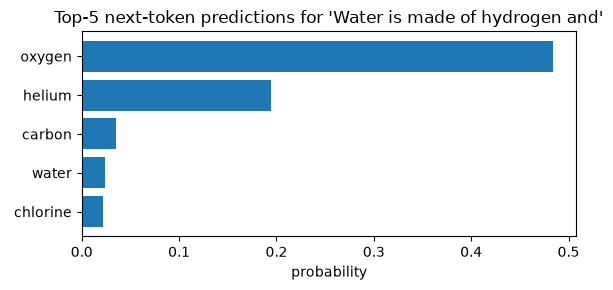

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 3))
labels = [model.to_string(t.item()) for t in top_tokens]
ax.barh(labels[::-1], top_probs.tolist()[::-1])
ax.set_xlabel("probability")
ax.set_title(f"Top-5 next-token predictions for {prompt!r}")
plt.tight_layout()
plt.show()


## What you should take away

- A `HookedTransformer` forward pass exposes every intermediate value through `run_with_cache`, keyed by
  a hook name like `blocks.{layer}.hook_resid_post`.
- The **residual stream** is the `(batch, position, d_model)` tensor that every later notebook treats as
  "the activations": it's what an SAE is trained to reconstruct (`PROPOSAL.md` § 4.2).
- You don't need to understand every hook name yet; `01_toy_sparse_autoencoder.ipynb` only needs the
  one pattern used above: pick a layer, grab `resid_post`, and you have a matrix of activations to work
  with.
